# Explorar el proyecto "analista de datos"

Este notebook abre los datos que armó el ETL del proyecto y los muestra paso a paso:

1. **Configuración**: dónde están los archivos (tu computadora, GitHub o Google Drive).
2. **Panel país-año** (`paises_anual.csv`): 217 países, 2000-2024, salud, economía, desigualdad y bienestar.
3. **Base unificada** (`master_paises_provincias.sqlite`): todas las tablas juntas, consultadas con SQL.
4. **Provincias argentinas**: la vista provincia × año.
5. **Los 5 KPIs multidimensionales**: se recalculan desde el SQL del proyecto.
6. **Cómo guardar todo online**: subir la carpeta a GitHub y abrir este notebook en Google Colab.

> **Cómo se usa un notebook.** Cada bloque gris es una *celda de código*. Se corre con el botón ▶
> o con `Shift + Enter`, de arriba hacia abajo. Los bloques de texto como este explican qué hace la
> celda siguiente. Si algo se rompe, *Entorno de ejecución → Reiniciar y ejecutar todo* (Colab) o
> *Kernel → Restart & Run All* (Jupyter) vuelve a empezar desde cero.

Solo usa **pandas** y **matplotlib**, que ya vienen instalados en Google Colab.

## 1. Configuración: ¿de dónde leo los archivos?

El notebook necesita tres cosas de la carpeta del proyecto (pesan unos 17 MB en total):

| Archivo | Qué es |
|---|---|
| `etl/datos_procesados/paises_anual.csv` | panel país × año |
| `etl/modelo_unificado/master_paises_provincias.sqlite` | la base unificada |
| `etl/kpis/kpis_multidimensionales.sql` (y `resultados/*.csv`) | las consultas de los KPIs |

El notebook los busca en este orden:

1. **En la carpeta del proyecto** (Jupyter o VS Code en tu computadora): sube carpeta por carpeta desde
   donde está guardado hasta encontrar `etl/` (por eso vive en `notebooks/`, al lado de `etl/`).
   Si los encuentra, no descarga nada.
2. **En Google Drive**, si completaste `CARPETA_DRIVE`.
3. **En GitHub** (lo normal en Colab): descarga el repositorio de `REPO_URL` con `git clone`.
   Ya viene con el repositorio del proyecto. Funciona directo si el repositorio es **público**;
   para uno privado, mirá la sección 6.
Para usar Google Drive: subí la carpeta del proyecto a tu Drive y poné en `CARPETA_DRIVE` su ruta
dentro de "Mi unidad", por ejemplo `"analista_de_datos"`. Colab te va a pedir permiso para leer tu Drive.

In [1]:
REPO_URL = "https://github.com/MarcosSantiago1/Word-Data"   # repositorio del proyecto
CARPETA_DRIVE = ""   # ej. "analista_de_datos" (ruta dentro de "Mi unidad")

import os
import subprocess
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
MARCA = Path("etl/datos_procesados/paises_anual.csv")   # archivo que identifica la carpeta del proyecto


def buscar_raiz(desde):
    """Sube carpeta por carpeta hasta encontrar la que tiene etl/datos_procesados/paises_anual.csv."""
    for carpeta in [desde, *desde.parents]:
        if (carpeta / MARCA).exists():
            return carpeta
    return None


RAIZ = buscar_raiz(Path.cwd().resolve())   # 1º: ¿el notebook ya está dentro de la carpeta del proyecto?

if RAIZ is not None:
    pass
elif CARPETA_DRIVE:
    from google.colab import drive   # solo existe dentro de Colab
    drive.mount("/content/drive")
    RAIZ = buscar_raiz(Path("/content/drive/MyDrive") / CARPETA_DRIVE)
elif REPO_URL:
    destino = Path("/content/proyecto" if EN_COLAB else "proyecto_github").resolve()
    if not destino.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(destino)], check=True)
    RAIZ = buscar_raiz(destino)

if RAIZ is None:
    raise FileNotFoundError(
        "No encontré etl/datos_procesados/paises_anual.csv. Revisá REPO_URL o CARPETA_DRIVE, "
        "o abrí el notebook desde la carpeta del proyecto."
    )

PANEL = RAIZ / "etl/datos_procesados/paises_anual.csv"
BASE = RAIZ / "etl/modelo_unificado/master_paises_provincias.sqlite"
SQL_KPIS = RAIZ / "etl/kpis/kpis_multidimensionales.sql"
KPIS_GUARDADOS = RAIZ / "etl/kpis/resultados"

print("Carpeta del proyecto:", RAIZ, "| en Colab:", EN_COLAB)
for archivo in [PANEL, BASE, SQL_KPIS]:
    estado = f"ok    {archivo.stat().st_size / 1e6:5.1f} MB" if archivo.exists() else "FALTA"
    print(f"  {estado}  {archivo.relative_to(RAIZ)}")

Carpeta del proyecto: /mnt/attach/project-files | en Colab: False
  ok      1.3 MB  etl/datos_procesados/paises_anual.csv
  ok     16.0 MB  etl/modelo_unificado/master_paises_provincias.sqlite
  ok      0.0 MB  etl/kpis/kpis_multidimensionales.sql


### Librerías y estilo de los gráficos

`pandas` maneja tablas (DataFrames), `sqlite3` abre la base y `matplotlib` dibuja.
La función `estilo()` deja los gráficos limpios: sin bordes de más y con una grilla suave.
En todos los gráficos, **Argentina va en azul** y el resto en gris, para ubicarla rápido.

In [2]:
import math
import re
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#b4b2a9"
plt.rcParams.update({
    "figure.figsize": (9, 5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})


MILES = FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))   # 10000 -> 10.000


def estilo(ax, titulo, x=None, y=None):
    ax.set_title(titulo, loc="left")
    if x: ax.set_xlabel(x)
    if y: ax.set_ylabel(y)
    return ax

## 2. Panel país-año (`paises_anual.csv`)

Es la tabla principal del paso 1 y el paso 2 del ETL. Cada fila es **un país en un año**
(clave: `iso3` + `anio`). `iso3` es el código de tres letras del país (ARG, CHL, USA...) y es la
llave con la que se unen todas las fuentes.

In [3]:
panel = pd.read_csv(PANEL)
print(f"{panel.shape[0]:,} filas × {panel.shape[1]} columnas | "
      f"{panel.iso3.nunique()} países | años {panel.anio.min()}-{panel.anio.max()}")
panel.head()

5,425 filas × 46 columnas | 217 países | años 2000-2024


,iso3,pais,region,nivel_ingreso,anio,poblacion,pib_pc_ppp,esperanza_vida,mortalidad_infantil,camas_hospital_x1000,medicos_x1000,suicidio_total_x100k,suicidio_hombres_x100k,suicidio_mujeres_x100k,gasto_salud_pct_pib,...,lorenz_acum_80,lorenz_acum_90,gini_aprox_desde_lorenz,ratio_quintil5_quintil1,ratio_palma,dieta_saludable_lcu_dia,dieta_saludable_ppa_dia,pct_no_puede_pagar_dieta_saludable,dieta_saludable_usd_mes,dieta_saludable_lcu_mes,salario_promedio_mensual_lcu,salario_promedio_mensual_usd,salario_promedio_mensual_ppa,felicidad,felicidad_ranking
0,ABW,Aruba,Latin America & Caribbean,High income,2000,90588,37618.992616,72.939,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ABW,Aruba,Latin America & Caribbean,High income,2001,91439,38827.467274,73.044,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ABW,Aruba,Latin America & Caribbean,High income,2002,92074,38195.317608,73.135,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ABW,Aruba,Latin America & Caribbean,High income,2003,93128,38182.392526,73.236,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ABW,Aruba,Latin America & Caribbean,High income,2004,95138,40101.787613,73.223,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Lista de columnas

`.columns` muestra los nombres. Los sufijos dicen la unidad: `_x1000` = por mil habitantes,
`_x100k` = por cien mil, `_pct_pib` = % del PIB, `_ppp`/`_ppa` = dólares a paridad de poder adquisitivo.

In [4]:
print(", ".join(panel.columns))

iso3, pais, region, nivel_ingreso, anio, poblacion, pib_pc_ppp, esperanza_vida, mortalidad_infantil, camas_hospital_x1000, medicos_x1000, suicidio_total_x100k, suicidio_hombres_x100k, suicidio_mujeres_x100k, gasto_salud_pct_pib, gasto_salud_pct_gasto_pub, gasto_educacion_pct_pib, tipo_cambio_lcu_por_usd, ppa_lcu_por_usd_intl, gini, ingreso_decil1_pct, ingreso_quintil1_pct, ingreso_quintil2_pct, ingreso_quintil3_pct, ingreso_quintil4_pct, ingreso_quintil5_pct, ingreso_decil10_pct, lorenz_acum_10, lorenz_acum_20, lorenz_acum_40, lorenz_acum_60, lorenz_acum_80, lorenz_acum_90, gini_aprox_desde_lorenz, ratio_quintil5_quintil1, ratio_palma, dieta_saludable_lcu_dia, dieta_saludable_ppa_dia, pct_no_puede_pagar_dieta_saludable, dieta_saludable_usd_mes, dieta_saludable_lcu_mes, salario_promedio_mensual_lcu, salario_promedio_mensual_usd, salario_promedio_mensual_ppa, felicidad, felicidad_ranking


### ¿Qué años tienen datos? (cobertura)

No todas las fuentes publican todos los años. Esta tabla muestra **qué % de los 217 países tiene dato**
en cada variable, para algunos años. Por eso el proyecto usa **2021** como año de referencia:
es el último con suicidio y con buena cobertura en casi todo.

In [5]:
variables = ["poblacion", "pib_pc_ppp", "esperanza_vida", "mortalidad_infantil", "medicos_x1000",
             "suicidio_total_x100k", "gasto_salud_pct_pib", "gasto_educacion_pct_pib",
             "gini", "dieta_saludable_ppa_dia", "salario_promedio_mensual_ppa", "felicidad"]
cobertura = (panel[panel.anio.isin([2000, 2010, 2019, 2021, 2023, 2024])]
             .groupby("anio")[variables].apply(lambda t: t.notna().mean() * 100)
             .round(0).astype(int).T)
cobertura.columns.name = "% de países con dato"
cobertura

% de países con dato,2000,2010,2019,2021,2023,2024
poblacion,100,100,100,100,100,100
pib_pc_ppp,88,91,92,92,91,90
esperanza_vida,100,100,100,100,100,100
mortalidad_infantil,90,90,90,90,90,90
medicos_x1000,48,60,62,57,27,0
suicidio_total_x100k,85,85,85,85,0,0
gasto_salud_pct_pib,85,87,89,89,88,3
gasto_educacion_pct_pib,55,63,77,77,56,18
gini,26,40,36,37,28,12
dieta_saludable_ppa_dia,0,0,76,76,76,76


### Una foto de Argentina en 2021

`.query()` filtra filas con una condición escrita como texto. `.T` (transpuesta) la muestra en vertical.

In [6]:
panel.query("iso3 == 'ARG' and anio == 2021")[["pais"] + variables].T.rename(columns=lambda c: "Argentina 2021")

,Argentina 2021
pais,Argentina
poblacion,45312281
pib_pc_ppp,26300.274261
esperanza_vida,73.948
mortalidad_infantil,8.5
medicos_x1000,5.384
suicidio_total_x100k,7.94
gasto_salud_pct_pib,6.348101
gasto_educacion_pct_pib,4.65393
gini,42.4


### Gráfico: la curva de Preston (ingreso vs. esperanza de vida, 2021)

Cada punto es un país. El eje horizontal está en **escala logarítmica**: cada marca es el doble o
diez veces más ingreso. La forma típica: la esperanza de vida sube rápido con los primeros dólares y
después se aplana (rendimientos decrecientes). Los países **por encima** de la nube viven más de lo que
"predice" su ingreso; esa idea es la base del KPI 1.

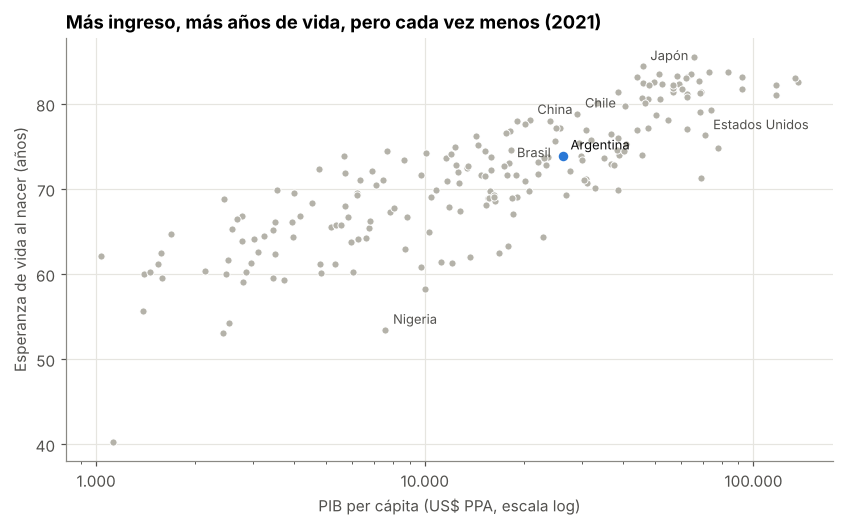

In [7]:
anio = 2021
d = panel.query("anio == @anio").dropna(subset=["pib_pc_ppp", "esperanza_vida"])
fig, ax = plt.subplots()
ax.scatter(d.pib_pc_ppp, d.esperanza_vida, s=22, color=GRIS, edgecolor="white", linewidth=0.6)
arg = d.query("iso3 == 'ARG'")
ax.scatter(arg.pib_pc_ppp, arg.esperanza_vida, s=60, color=AZUL, edgecolor="white", linewidth=1.5, zorder=3)
nombres = {"ARG": "Argentina", "CHL": "Chile", "BRA": "Brasil", "USA": "Estados Unidos",
           "JPN": "Japón", "NGA": "Nigeria", "CHN": "China"}
for iso, nombre in nombres.items():
    fila = d.query("iso3 == @iso")
    if len(fila):
        ax.annotate(nombre, (fila.pib_pc_ppp.iloc[0], fila.esperanza_vida.iloc[0]),
                    xytext=(5, 4), textcoords="offset points", fontsize=8.5,
                    color="#0b0b0b" if iso == "ARG" else "#52514e")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(MILES)
estilo(ax, f"Más ingreso, más años de vida, pero cada vez menos ({anio})",
       "PIB per cápita (US$ PPA, escala log)", "Esperanza de vida al nacer (años)");

### Gráfico: Argentina vs. el resto de América Latina en el tiempo

`groupby("anio").median()` calcula, año por año, la **mediana** de la región (el país del medio:
no se deja arrastrar por extremos como hace el promedio). La caída de 2020-2021 es el COVID.

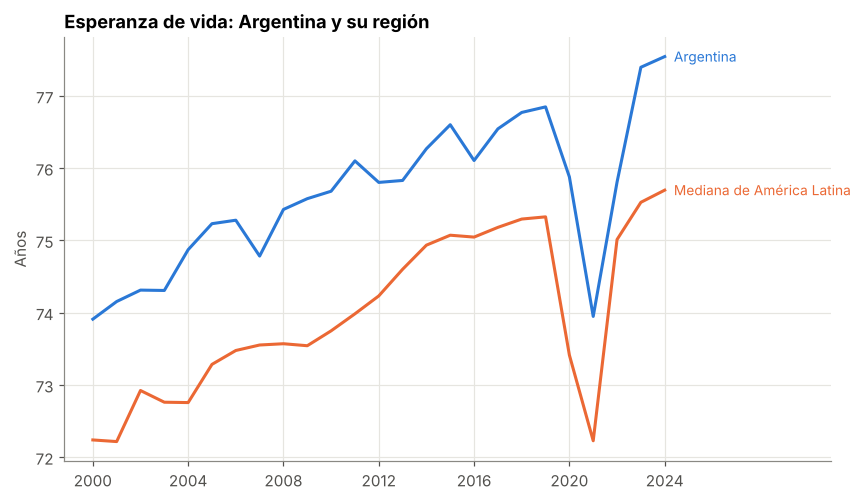

In [8]:
latam = panel[panel.region == "Latin America & Caribbean"]
mediana = latam.groupby("anio").esperanza_vida.median()
argentina = panel.query("iso3 == 'ARG'").set_index("anio").esperanza_vida

fig, ax = plt.subplots()
ax.plot(argentina.index, argentina, color=AZUL, linewidth=2)
ax.plot(mediana.index, mediana, color=NARANJA, linewidth=2)
ax.annotate("Argentina", (argentina.dropna().index[-1], argentina.dropna().iloc[-1]),
            xytext=(6, 0), textcoords="offset points", color=AZUL, va="center", fontsize=9)
ax.annotate("Mediana de América Latina", (mediana.dropna().index[-1], mediana.dropna().iloc[-1]),
            xytext=(6, 0), textcoords="offset points", color=NARANJA, va="center", fontsize=9)
ax.set_xlim(right=panel.anio.max() + 7)
ax.set_xticks(range(2000, panel.anio.max() + 1, 4))
estilo(ax, "Esperanza de vida: Argentina y su región", None, "Años");

## 3. La base unificada (SQLite)

`construir_master.py` junta **todas** las fuentes del proyecto (Banco Mundial, OMS, alianzas,
Factbook, provincias...) en un único archivo SQLite. Un archivo SQLite es una base de datos completa
en un solo archivo: se consulta con **SQL** y no necesita servidor.

El modelo sigue una convención de nombres:

| Prefijo | Qué guarda | Ejemplo |
|---|---|---|
| `dim_` | catálogos (una fila por país, provincia, región...) | `dim_pais` |
| `hecho_` | mediciones (una fila por país/provincia y año) | `hecho_pais_anual` |
| `rel_` | relaciones entre dos cosas | `rel_pais_frontera` |
| `v_` | vistas: consultas guardadas que ya juntan todo | `v_pais_anual` |
| `ref_` | documentación de la propia base | `ref_diccionario_columna` |

Abrimos la base en **modo solo lectura** (`mode=ro`) para no modificarla por accidente.
La función `conectar()` además agrega `ln`, `sqrt` y `exp` si la versión de SQLite no los trae
(algunas instalaciones vienen sin funciones matemáticas y los KPIs las usan).

In [9]:
def conectar():
    con = sqlite3.connect(f"file:{BASE}?mode=ro", uri=True)
    try:
        con.execute("SELECT ln(2), sqrt(4), exp(1)")
    except sqlite3.OperationalError:   # SQLite compilado sin funciones matemáticas
        con.create_function("ln", 1, lambda x: math.log(x) if x is not None and x > 0 else None, deterministic=True)
        con.create_function("sqrt", 1, lambda x: math.sqrt(x) if x is not None and x >= 0 else None, deterministic=True)
        con.create_function("exp", 1, lambda x: math.exp(x) if x is not None else None, deterministic=True)
    return con


con = conectar()


def sql(consulta, **parametros):
    """Corre una consulta SQL y devuelve un DataFrame. Los :parametros se pasan por nombre."""
    return pd.read_sql_query(consulta, con, params=parametros)


print("SQLite", sqlite3.sqlite_version)
sql("SELECT type AS tipo, COUNT(*) AS cantidad FROM sqlite_master "
    "WHERE type IN ('table', 'view') GROUP BY type")

SQLite 3.45.1


,tipo,cantidad
0,table,62
1,view,15


### Catálogo: qué tablas hay, cuántas filas y de qué fuente

La propia base trae su índice en `ref_catalogo_tabla`.

In [10]:
sql("SELECT tabla, tipo, grano, fuente, filas, anio_min, anio_max FROM ref_catalogo_tabla ORDER BY tipo, tabla")

,tabla,tipo,grano,fuente,filas,anio_min,anio_max
0,dim_acuerdo_comercial,dim,acuerdo_id,DESTA 2.0,842,NaN,NaN
1,dim_nivel_ingreso,dim,nivel_ingreso_codigo,Banco Mundial API,4,NaN,NaN
2,dim_organizacion,dim,organizacion_codigo,alianzas/membresias_organizaciones.csv,48,NaN,NaN
3,dim_pais,dim,"pais_id (también único: iso3, iso2)","maestros/paises_maestro.csv (ISO 3166-1, Banco...",251,NaN,NaN
4,dim_rama_cepal,dim,rama_nro,CEPAL-MECON,52,NaN,NaN
5,dim_region_bm,dim,region_bm_codigo,Banco Mundial API,7,NaN,NaN
6,dim_region_geografica,dim,region_geografica_id (código M49),ONU M49 (lukes/ISO-3166-Countries-with-Regiona...,29,NaN,NaN
7,dim_region_subnacional,dim,region_subnacional_id,"INDEC, regiones de la EPH",6,NaN,NaN
8,dim_subdivision,dim,subdivision_id (también único: codigo),maestros/subdivisiones_maestro.csv (ISO 3166-2...,3591,NaN,NaN
9,hecho_pais_anual,hecho,"pais_id, anio","Banco Mundial, OMS, ILOSTAT, World Happiness R...",5425,2000.0,2024.0


### Diccionario: buscar una columna

`ref_diccionario_columna` dice en qué tabla está cada columna, su tipo, su unidad y qué % de nulos tiene.
Cambiá la palabra entre `%` para buscar otra cosa (por ejemplo `%gini%` o `%petroleo%`).

In [11]:
sql("SELECT tabla, columna, unidad, pct_nulos FROM ref_diccionario_columna "
    "WHERE columna LIKE :buscar ORDER BY tabla", buscar="%felicidad%")

,tabla,columna,unidad,pct_nulos
0,hecho_pais_anual,felicidad,None,64.2
1,hecho_pais_anual,felicidad_ranking,None,64.2


### Una consulta de ejemplo

`v_pais_anual` es la vista país × año ya lista (nombres en español, continente, nivel de ingreso).
Esta consulta arma un **ranking de América del Sur en 2021**: `WHERE` filtra, `ORDER BY` ordena.
Los valores que cambian (año, continente) se pasan como `:parametros` en vez de pegarlos en el texto.

In [12]:
sql("""
    SELECT pais, esperanza_vida, mortalidad_infantil, gasto_salud_pct_pib,
           ROUND(pib_pc_ppp) AS pib_pc_ppp, felicidad
    FROM v_pais_anual
    WHERE anio = :anio
      AND iso3 IN ('ARG','BOL','BRA','CHL','COL','ECU','GUY','PRY','PER','SUR','URY','VEN')
    ORDER BY esperanza_vida DESC
""", anio=2021)

,pais,esperanza_vida,mortalidad_infantil,gasto_salud_pct_pib,pib_pc_ppp,felicidad
0,Chile,78.876,5.8,5.218429,29107.0,6.172
1,Uruguay,75.434,6.1,6.549376,29432.0,6.474
2,Argentina,73.948,8.5,6.348101,26300.0,5.967
3,Brasil,73.038,12.7,4.306740,18076.0,6.293
4,Ecuador,72.746,11.3,5.314744,13507.0,5.533
5,Colombia,72.698,11.5,6.645015,17383.0,5.781
6,Perú,71.596,11.9,4.461303,15286.0,5.559
7,Venezuela,71.536,21.2,1.375254,NaN,4.925
8,Surinam,68.943,16.2,3.270929,18458.0,NaN
9,Paraguay,68.108,16.0,4.466102,15401.0,5.578


### Un JOIN: unir tablas por sus claves

`rel_pais_frontera` guarda qué países limitan entre sí (del CIA World Factbook), identificados con
`pais_id`, el número interno de `dim_pais`. Con `JOIN` traducimos ese número a `iso3` y le pegamos a
cada vecino de Argentina sus datos de `v_pais_anual`. Primero miramos las columnas con `PRAGMA`.

In [13]:
print(sql("PRAGMA table_info(rel_pais_frontera)").name.tolist())

['pais_id', 'codigo_gec', 'vecino_pais_id', 'vecino_codigo_gec', 'vecino_nombre_factbook', 'frontera_km', 'nota']


In [14]:
sql("""
    SELECT v.nombre_es AS vecino, f.frontera_km,
           ROUND(p.pib_pc_ppp) AS pib_pc_ppp, p.esperanza_vida, p.felicidad
    FROM rel_pais_frontera AS f
    JOIN dim_pais          AS a ON a.pais_id = f.pais_id          -- el país de origen
    JOIN dim_pais          AS v ON v.pais_id = f.vecino_pais_id   -- el vecino
    LEFT JOIN v_pais_anual AS p ON p.iso3 = v.iso3 AND p.anio = 2021
    WHERE a.iso3 = 'ARG'
    ORDER BY f.frontera_km DESC
""")

,vecino,frontera_km,pib_pc_ppp,esperanza_vida,felicidad
0,Chile,6691.0,29107.0,78.876,6.172
1,Paraguay,2531.0,15401.0,68.108,5.578
2,Brasil,1263.0,18076.0,73.038,6.293
3,Bolivia,942.0,11202.0,61.427,5.600
4,Uruguay,541.0,29432.0,75.434,6.474


## 4. Provincias argentinas

`v_subdivision_anual` es la vista provincia × año (24 jurisdicciones, 2004-2024): valor agregado,
petróleo, ganado, turismo, salarios, finanzas públicas, pobreza estimada y más.
Este gráfico muestra el **PBG per cápita** (producto por habitante, en pesos constantes de 2004).

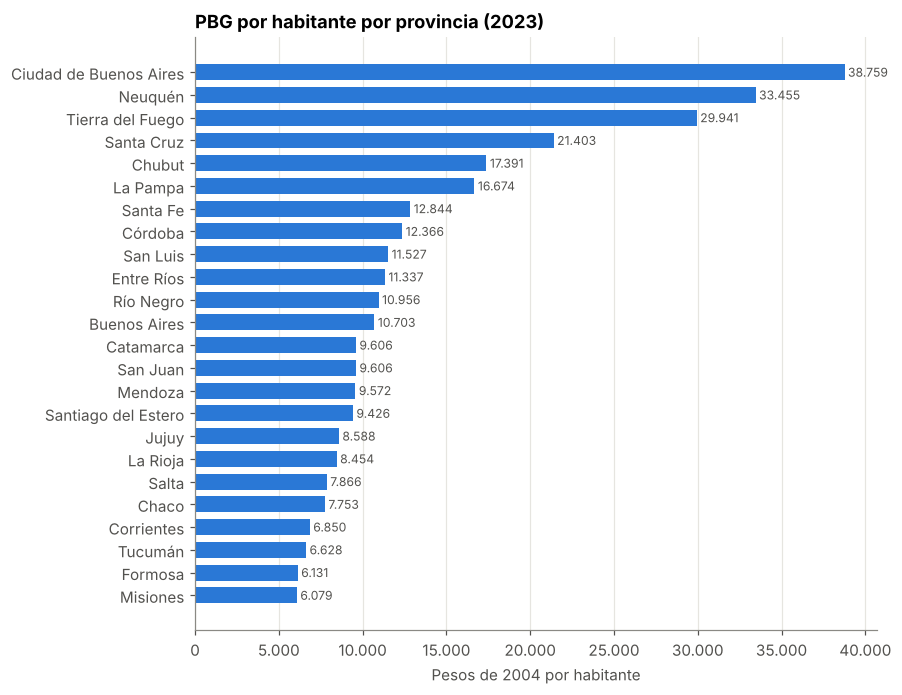

In [15]:
pbg = sql("""
    SELECT subdivision AS provincia, anio, pbg_per_capita_pesos_2004 AS pbg_pc
    FROM v_subdivision_anual
    WHERE iso3 = 'ARG' AND pbg_per_capita_pesos_2004 IS NOT NULL
      AND anio = (SELECT MAX(anio) FROM v_subdivision_anual WHERE pbg_per_capita_pesos_2004 IS NOT NULL)
    ORDER BY pbg_pc
""")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(pbg.provincia, pbg.pbg_pc, color=AZUL, height=0.7)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(MILES)
for y, v in enumerate(pbg.pbg_pc):
    ax.text(v, y, f" {v:,.0f}".replace(",", "."), va="center", fontsize=8, color="#52514e")
estilo(ax, f"PBG por habitante por provincia ({pbg.anio.iloc[0]})", "Pesos de 2004 por habitante");

## 5. Los 5 KPIs multidimensionales

Los KPIs están escritos en SQL en `etl/kpis/kpis_multidimensionales.sql` (la explicación completa de
cada uno está en `KPIS_MULTIDIMENSIONALES.md`). Cada bloque empieza con una línea `-- name: CODIGO`,
crea una **vista temporal** (que no toca la base) y termina con un `SELECT`.

La celda siguiente hace lo mismo que `calcular_kpis.py`: separa los bloques, los corre en orden y
guarda cada resultado en un diccionario `kpis`. Después compara con los CSV que dejó la última corrida
del ETL, para confirmar que da lo mismo.

In [16]:
def bloques(texto):
    """Devuelve [(codigo, [sentencias])] separando el archivo por las líneas '-- name:'."""
    partes = re.split(r"^-- name:\s*(\S+)\s*$", texto, flags=re.M)
    for codigo, cuerpo in zip(partes[1::2], partes[2::2]):
        sentencias, actual = [], ""
        for linea in cuerpo.splitlines(keepends=True):
            actual += linea
            if sqlite3.complete_statement(actual):
                if actual.strip():
                    sentencias.append(actual.strip())
                actual = ""
        yield codigo, sentencias


kpis = {}
for codigo, sentencias in bloques(SQL_KPIS.read_text(encoding="utf-8")):
    for s in sentencias[:-1]:          # DROP / CREATE TEMP VIEW
        con.execute(s)
    kpis[codigo] = pd.read_sql_query(sentencias[-1], con)   # el SELECT final

resumen = []
for codigo, tabla in kpis.items():
    guardado = KPIS_GUARDADOS / f"{codigo}.csv"
    filas_guardadas = len(pd.read_csv(guardado)) if guardado.exists() else None
    resumen.append({"kpi": codigo, "filas": len(tabla), "filas en el CSV guardado": filas_guardadas,
                    "columnas": ", ".join(tabla.columns[:6]) + " ..."})
pd.DataFrame(resumen)

,kpi,filas,filas en el CSV guardado,columnas
0,KPI1_SAL_EFI_IESE,186,186,"iso3, pais, continente, nivel_ingreso, pib_pc_..."
1,KPI2_PSI_PARADOJA_IPFS,142,142,"iso3, pais, continente, nivel_ingreso, felicid..."
2,KPI3_GEO_EXPO_IEG,213,213,"iso3, pais, continente, nivel_ingreso, poblaci..."
3,KPI4_SOC_TENSION_ITID,130,130,"iso3, pais, continente, fracc_etnica, fracc_re..."
4,KPI4b_ITID_POR_CUARTIL_Y_FORMA_ESTADO,8,8,"cuartil_itid, forma_estado, paises, itid_prome..."
5,KPI5_PROV_RENTISMO_IRFH,24,24,"codigo, provincia, pct_vab_sector_publico, pre..."
6,KPI5b_CORRELACION_RENTISMO_CONTINUIDAD,1,1,"provincias, pearson_rentismo_vs_continuidad, p..."


### KPI 1 · Índice de Eficiencia Sanitaria Estructural (IESE, 2021)

Mide cuánta salud (esperanza de vida y mortalidad infantil **por encima de lo que predice el ingreso**)
logra cada país en relación con lo que gasta el Estado en salud. Positivo = más salud con menos gasto.

In [17]:
k1 = kpis["KPI1_SAL_EFI_IESE"]
cols = ["pais", "continente", "pib_pc_ppp", "esperanza_vida", "gasto_salud_publico_pct_pib",
        "anios_sobre_curva_preston", "iese", "cuadrante"]
print("Los 10 más eficientes:")
display(k1[cols].head(10))
print("Argentina:")
display(k1.query("iso3 == 'ARG'")[cols])

Los 10 más eficientes:


,pais,continente,pib_pc_ppp,esperanza_vida,gasto_salud_publico_pct_pib,anios_sobre_curva_preston,iese,cuadrante
0,Vanuatu,Oceanía,3546.0,70.0,1.23,6.66,2.172,"eficiente (más salud, menos gasto)"
1,Burundi,África,1032.0,62.1,2.22,5.77,2.039,"eficiente (más salud, menos gasto)"
2,Islas Salomón,Oceanía,2450.0,68.9,3.45,7.68,1.977,"eficiente (más salud, menos gasto)"
3,Siria,Asia,4766.0,72.4,1.09,7.46,1.842,"eficiente (más salud, menos gasto)"
4,Malaui,África,1688.0,64.8,1.36,5.68,1.705,"eficiente (más salud, menos gasto)"
5,Sri Lanka,Asia,14316.0,76.3,2.26,5.12,1.644,"eficiente (más salud, menos gasto)"
6,Tonga,Oceanía,6930.0,72.1,3.28,5.06,1.617,"eficiente (más salud, menos gasto)"
7,Palestina,Asia,5663.0,73.9,4.27,7.96,1.534,"intensivo (más salud, más gasto)"
8,Madagascar,África,1577.0,62.5,0.75,3.79,1.511,"eficiente (más salud, menos gasto)"
9,Kirguistán,Asia,5736.0,71.9,2.96,5.90,1.367,"eficiente (más salud, menos gasto)"


Argentina:


,pais,continente,pib_pc_ppp,esperanza_vida,gasto_salud_publico_pct_pib,anios_sobre_curva_preston,iese,cuadrante
146,Argentina,América,26300.0,73.9,6.35,-0.64,-0.671,"ineficiente (menos salud, más gasto)"


### KPI 2 · Paradoja felicidad-suicidio (IPFS)

Cruza la felicidad declarada (World Happiness Report) con la tasa de suicidio (OMS), ambas pasadas
a **puntaje z** (a cuántos desvíos del promedio está cada país). Arriba a la derecha está la
"paradoja": países que se declaran felices y aun así tienen suicidio alto.

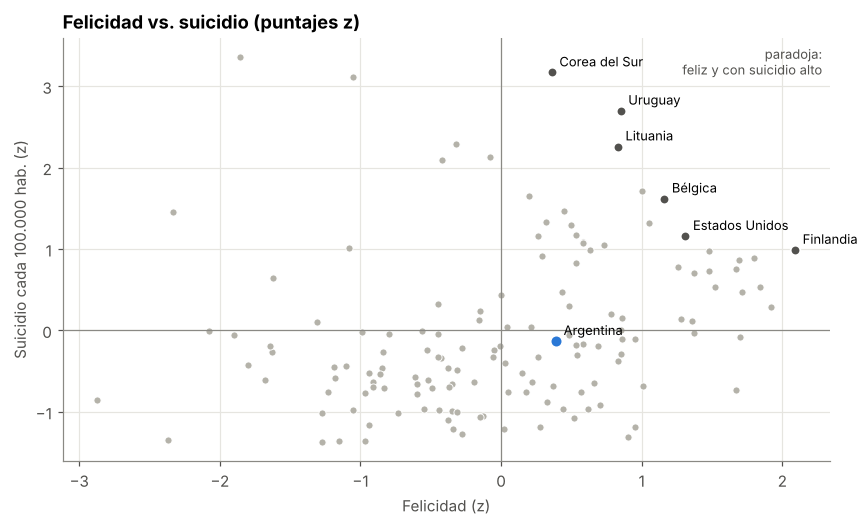

In [18]:
k2 = kpis["KPI2_PSI_PARADOJA_IPFS"].dropna(subset=["z_felicidad", "z_suicidio"])
fig, ax = plt.subplots()
ax.axhline(0, color="#8a8984", linewidth=0.8)
ax.axvline(0, color="#8a8984", linewidth=0.8)
ax.scatter(k2.z_felicidad, k2.z_suicidio, s=22, color=GRIS, edgecolor="white", linewidth=0.6)
for iso in ["ARG", "USA", "BEL", "FIN", "URY", "KOR", "LTU"]:
    fila = k2.query("iso3 == @iso")
    if len(fila):
        ax.scatter(fila.z_felicidad, fila.z_suicidio, s=40 if iso != "ARG" else 60,
                   color=AZUL if iso == "ARG" else "#52514e", edgecolor="white", linewidth=1.2, zorder=3)
        ax.annotate(fila.pais.iloc[0], (fila.z_felicidad.iloc[0], fila.z_suicidio.iloc[0]),
                    xytext=(5, 4), textcoords="offset points", fontsize=8.5)
ax.text(0.99, 0.98, "paradoja:\nfeliz y con suicidio alto", transform=ax.transAxes,
        ha="right", va="top", fontsize=8.5, color="#52514e")
estilo(ax, "Felicidad vs. suicidio (puntajes z)", "Felicidad (z)", "Suicidio cada 100.000 hab. (z)");

### KPI 3 · Exposición geoeconómica (IEG)

Qué tan concentradas están las exportaciones en 5 socios y cuánto de eso está "respaldado" por
acuerdos comerciales o alianzas de defensa. Más alto = más expuesto.

In [19]:
k3 = kpis["KPI3_GEO_EXPO_IEG"]
display(k3[["pais", "pct_export_top5", "hhi_top5", "pct_top5_con_respaldo", "ieg", "nivel"]].head(10))
display(k3.query("iso3 == 'ARG'")[["pais", "pct_export_top5", "hhi_top5", "pct_top5_con_respaldo", "ieg", "nivel"]])

,pais,pct_export_top5,hhi_top5,pct_top5_con_respaldo,ieg,nivel
0,Gambia,97.0,8471.0,3.1,8466.0,exposición alta
1,Tuvalu,99.0,7791.0,1.0,7790.0,exposición alta
2,Kiribati,97.0,7275.0,1.0,7274.0,exposición alta
3,Nauru,96.0,6232.0,0.0,6232.0,exposición alta
4,Nueva Caledonia,92.0,5728.0,2.2,5724.0,exposición alta
5,Mali,95.0,5581.0,1.1,5580.0,exposición alta
6,Burkina Faso,90.0,5306.0,5.6,5293.0,exposición alta
7,Eritrea,100.0,5192.0,2.0,5190.0,exposición alta
8,República Democrática del Congo,85.0,4837.0,10.6,4810.0,exposición alta
9,Sierra Leona,85.0,4575.0,14.1,4525.0,exposición alta


,pais,pct_export_top5,hhi_top5,pct_top5_con_respaldo,ieg,nivel
135,Argentina,47.0,549.0,83.0,64.0,exposición baja


### KPI 4 · Tensión identitaria-distributiva (ITID)

Combina diversidad étnica y religiosa (fraccionalización) con desigualdad (Gini). La segunda tabla
compara el promedio por cuartil de ITID entre países **federales** y **unitarios**.

In [20]:
display(kpis["KPI4_SOC_TENSION_ITID"].head(10))
kpis["KPI4b_ITID_POR_CUARTIL_Y_FORMA_ESTADO"].drop(columns="paises_iso3")

,iso3,pais,continente,fracc_etnica,fracc_religiosa,gini,itid,felicidad,forma_estado,tipo_regimen,tipo_gobierno
0,AGO,Angola,África,0.735,0.664,51.3,35.9,NaN,unitario,régimen constitucional,presidential republic
1,CAF,República Centroafricana,África,0.834,0.770,43.0,34.5,NaN,unitario,régimen constitucional,presidential republic
2,CMR,Camerún,África,0.863,0.720,42.2,33.4,4.89,unitario,régimen constitucional,presidential republic
3,ZMB,Zambia,África,0.898,0.391,51.5,33.2,3.91,unitario,régimen constitucional,presidential republic
4,SUR,Surinam,América,0.811,0.820,39.2,32.0,NaN,unitario,régimen constitucional,presidential republic
5,BRA,Brasil,América,0.595,0.646,51.5,31.9,6.49,federal,régimen constitucional,federal presidential republic
6,MWI,Malaui,África,0.807,0.765,38.5,30.2,3.26,unitario,régimen constitucional,presidential republic
7,GAB,Gabón,África,0.840,0.678,38.0,28.8,5.12,unitario,régimen constitucional,presidential republic
8,TCD,Chad,África,0.869,0.631,37.4,28.0,4.38,unitario,régimen constitucional,presidential republic
9,UGA,Uganda,África,0.833,0.623,38.2,27.8,4.46,unitario,régimen constitucional,presidential republic


,cuartil_itid,forma_estado,paises,itid_promedio,felicidad_promedio
0,1,federal,2,7.9,4.69
1,1,unitario,31,7.8,5.81
2,2,federal,5,13.5,6.33
3,2,unitario,28,13.5,5.83
4,3,federal,4,18.9,6.49
5,3,unitario,28,19.1,5.39
6,4,federal,7,25.2,5.96
7,4,unitario,25,27.1,5.17


### KPI 5 · Rentismo fiscal provincial (IRFH)

Para las 24 provincias: peso del sector público en la economía, poca recaudación propia y pobreza,
junto con cuántos años gobierna la misma familia política. Más alto = más "rentista"
(en naranja, las provincias por encima del promedio).

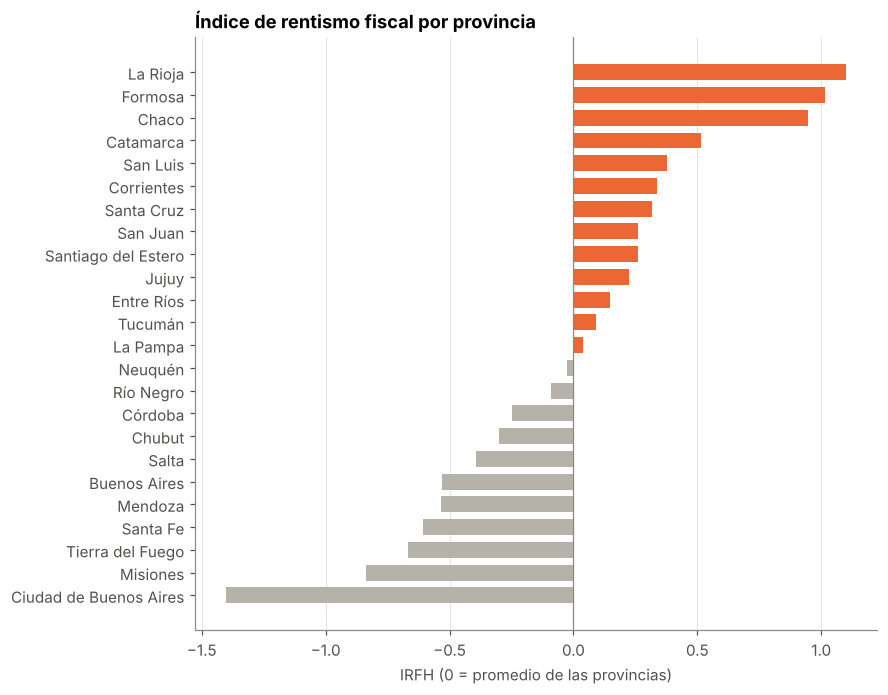

,provincias,pearson_rentismo_vs_continuidad,pearson_rentismo_vs_pobreza
0,24,0.223,0.381


In [21]:
k5 = kpis["KPI5_PROV_RENTISMO_IRFH"].sort_values("irfh")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(k5.provincia, k5.irfh, color=[NARANJA if v >= 0 else GRIS for v in k5.irfh], height=0.7)
ax.axvline(0, color="#8a8984", linewidth=0.8)
ax.grid(axis="y", visible=False)
estilo(ax, "Índice de rentismo fiscal por provincia", "IRFH (0 = promedio de las provincias)")
plt.show()
kpis["KPI5b_CORRELACION_RENTISMO_CONTINUIDAD"]

### Guardar los resultados

Con `GUARDAR = True`, la celda escribe cada KPI como CSV en una carpeta `resultados_notebook/` al lado
del notebook. En Colab, además, los empaqueta en un `.zip` y lo descarga a tu computadora
(los archivos de Colab se borran al cerrar la sesión).

In [22]:
GUARDAR = False

if GUARDAR:
    carpeta = Path("resultados_notebook")
    carpeta.mkdir(exist_ok=True)
    for codigo, tabla in kpis.items():
        tabla.to_csv(carpeta / f"{codigo}.csv", index=False)
    print("Guardados", len(kpis), "CSV en", carpeta.resolve())
    if EN_COLAB:
        import shutil
        from google.colab import files
        files.download(shutil.make_archive("resultados_notebook", "zip", carpeta))

## 6. Cómo guardar todo online (GitHub + Google Colab)

**GitHub** guarda la carpeta del proyecto (código, guías y datos) con su historial de cambios.
**Google Colab** es Jupyter en el navegador, gratis con una cuenta de Google: abre este notebook
directamente desde GitHub, sin instalar nada.

### Paso 1. Crear el repositorio

1. Creá una cuenta en [github.com](https://github.com) (si no tenés).
2. Arriba a la derecha: **+ → New repository**. Nombre, por ejemplo, `analista-de-datos`.
3. Elegí **Public** si querés que Colab lo abra sin más pasos (todos los datos vienen de fuentes
   abiertas). **Private** también sirve; ver el paso 4.
4. Tildá **Add a README file** y **Create repository**.

### Paso 2. Subir los archivos

Dos límites de GitHub a tener en cuenta: **ningún archivo puede pesar más de 100 MB**, y desde la
página web se suben como mucho 25 MB por archivo y 100 archivos por vez. En este proyecto solo
`etl/fuentes_nuevas/crudos/ccpcnc_v5.zip` (118 MB, un crudo de constituciones) pasa el límite.
El archivo `.gitignore` en la raíz del proyecto ya lo deja afuera, junto con los `__pycache__`
y las copias viejas de `etl/historial/`.

- **Opción A, versión liviana desde la web (5 minutos).** En el repositorio: **Add file → Upload files**
  y arrastrá, respetando las carpetas: la carpeta `notebooks/`, `etl/datos_procesados/`,
  `etl/kpis/` y `etl/modelo_unificado/` (solo `master_paises_provincias.sqlite`, `esquema.sql` y
  `GUIA_MODELO_UNIFICADO.md`). Con eso este notebook ya corre. Después podés sumar `codigo_python/`
  y las guías `etl/GUIA_*.md`.
- **Opción B, el proyecto entero (recomendada para tener todo).** Instalá
  [GitHub Desktop](https://desktop.github.com), **File → Clone repository** con tu repositorio,
  copiá adentro todo el contenido de la carpeta del proyecto, escribí un mensaje (por ejemplo
  "primera versión") y tocá **Commit to main** y luego **Push origin**. Desde la terminal es lo mismo:

  ```bash
  cd carpeta-del-proyecto
  git init -b main
  git add .
  git commit -m "Primera versión del proyecto"
  git remote add origin https://github.com/MarcosSantiago1/Word-Data.git
  git push -u origin main
  ```

### Paso 3. Abrir el notebook en Colab

Entrá a esta dirección:

[colab.research.google.com/github/MarcosSantiago1/Word-Data/blob/main/notebooks/explorar_proyecto.ipynb](https://colab.research.google.com/github/MarcosSantiago1/Word-Data/blob/main/notebooks/explorar_proyecto.ipynb)

(o en [colab.research.google.com](https://colab.research.google.com): **Archivo → Abrir notebook →
GitHub**, pegá la dirección del repositorio y elegí el notebook). Después corré todo con
**Entorno de ejecución → Ejecutar todas**: la sección 1 ya tiene `REPO_URL` apuntando al repositorio.

Para guardar los cambios que hagas en Colab: **Archivo → Guardar una copia en GitHub** (vuelve al
repositorio) o **Guardar una copia en Drive**.

### Paso 4. Si el repositorio es privado

Colab puede *abrir* el notebook de un repositorio privado (te pide autorizar tu cuenta de GitHub,
tildando "Include private repos"), pero el `git clone` de la sección 1 no tiene tu contraseña.
Lo más simple: subí también la carpeta del proyecto a Google Drive y usá `CARPETA_DRIVE` en vez de
`REPO_URL`.

### Cuando el ETL se actualice

La actualización mensual (día 16) rehace los CSV y la base. Para que GitHub tenga la versión nueva,
volvé a subir los archivos que cambiaron (en GitHub Desktop aparecen solos en la lista de cambios:
commit y push).